# Earthwise Butchery Meat Freshness MLOps Project

This image-classification project predicts dataset labels for meat photos: **fresh**, **half-fresh**, or **spoiled**. It uses non-tabular image data, with labels read from the dataset annotations. It does **not** determine whether food is safe to eat.

In [1]:
import io
import os
import sys
import tempfile
import zipfile
from pathlib import Path

if 'COLAB_RELEASE_TAG' in os.environ:
    os.chdir('/content')
    project_dir = Path('/content/kudakwashe-mlops-classification-pipeline')
    if not (project_dir / 'scripts' / 'import_freshness_dataset.py').is_file():
        if project_dir.exists():
            raise RuntimeError('Refresh the Colab clone after updating the GitHub repository.')
        !git clone https://github.com/kudakwashechikovo17/kudakwashe-mlops-classification-pipeline.git /content/kudakwashe-mlops-classification-pipeline
    os.chdir(project_dir)
    %pip install -q -r requirements.txt

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'train.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Could not find the project folder containing scripts/train.py.')
sys.path.insert(0, str(ROOT))
from scripts.import_freshness_dataset import import_dataset
from src.model import DATA_DIR, DEFAULT_CLASS_NAMES

TRAIN_DIR = DATA_DIR / 'train'
TEST_DIR = DATA_DIR / 'test'
if 'COLAB_RELEASE_TAG' in os.environ and not (TRAIN_DIR.is_dir() and TEST_DIR.is_dir()):
    from google.colab import files
    uploaded = files.upload()
    zip_names = [name for name in uploaded if name.lower().endswith('.zip')]
    if not zip_names:
        raise FileNotFoundError('Upload a ZIP of the extracted dataset containing train/ and valid/ folders.')
    with tempfile.TemporaryDirectory(prefix='meat-freshness-source-') as temporary:
        extraction_root = Path(temporary).resolve()
        with zipfile.ZipFile(io.BytesIO(uploaded[zip_names[0]])) as archive:
            for member in archive.infolist():
                destination = (extraction_root / member.filename).resolve()
                try:
                    destination.relative_to(extraction_root)
                except ValueError as exc:
                    raise ValueError(f'Unsafe archive path: {member.filename}') from exc
            archive.extractall(extraction_root)
        candidates = [
            path.parent.parent
            for path in extraction_root.rglob('train/_classes.csv')
            if (path.parent.parent / 'valid' / '_classes.csv').is_file()
        ]
        if len(candidates) != 1:
            raise ValueError(f'Expected one dataset root with train/ and valid/ CSVs; found {len(candidates)}.')
        print('Imported dataset counts:', import_dataset(candidates[0], DATA_DIR))

if not (TRAIN_DIR.is_dir() and TEST_DIR.is_dir()):
    raise FileNotFoundError(
        f'Import the dataset first with: python scripts/import_freshness_dataset.py "<extracted dataset folder>". '
        f'Expected train and test splits under {DATA_DIR}.'
    )
CLASS_NAMES = DEFAULT_CLASS_NAMES
print('Project root:', ROOT)
print('Active data directory:', DATA_DIR)
print('Classes:', CLASS_NAMES)

Project root: C:\Users\pc\kudakwashe-mlops-classification-pipeline
Active data directory: C:\Users\pc\kudakwashe-mlops-classification-pipeline\data\meat_freshness
Classes: ('fresh', 'half_fresh', 'spoiled')


## 1. Data acquisition and preprocessing

The downloaded dataset provides `train/` and `valid/` folders with one-hot labels in `_classes.csv`. The import script validates those labels and makes class folders, keeping the provided validation images separate as the held-out evaluation split. Images are EXIF-corrected, converted to RGB, resized, normalized, and represented by low-resolution RGB pixels plus per-channel color histograms.

Training feature matrix: (1815, 792)
Test feature matrix: (451, 792)
Training images per class: {'fresh': 675, 'half_fresh': 630, 'spoiled': 510}


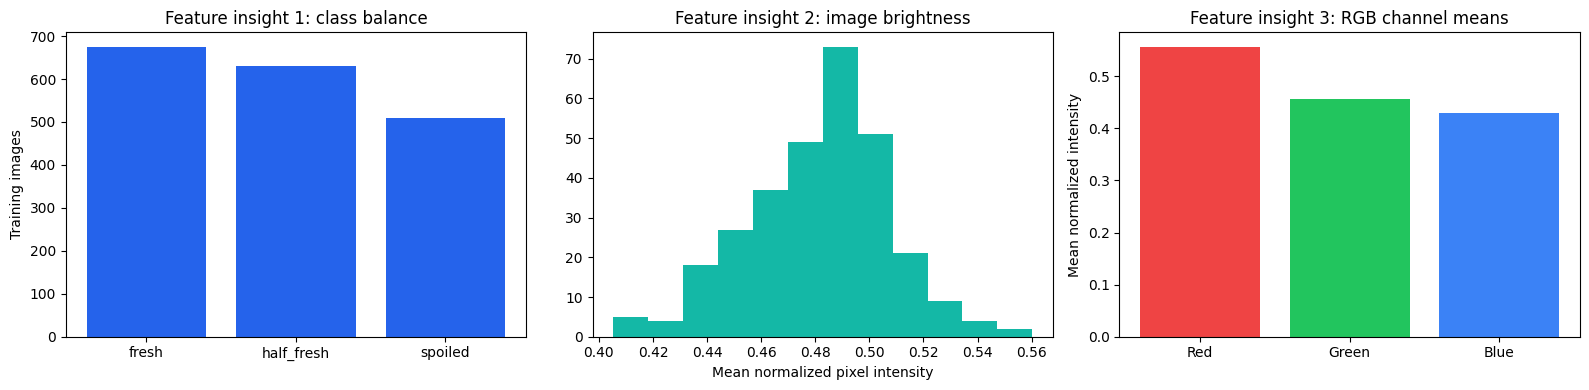

Interpretation: class balance reveals collection gaps; brightness and channel means describe image appearance but can also reflect lighting/background bias.


In [2]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from src.preprocessing import IMAGE_EXTENSIONS, load_classification_split, preprocess_image

TRAIN_DIR = DATA_DIR / 'train'
TEST_DIR = DATA_DIR / 'test'
X_train, y_train, class_names = load_classification_split(TRAIN_DIR)
X_test, y_test, test_class_names = load_classification_split(TEST_DIR, class_names)
assert class_names == test_class_names, 'Train/test class order differs.'
class_counts = {name: int((y_train == index).sum()) for index, name in enumerate(class_names)}
print('Training feature matrix:', X_train.shape)
print('Test feature matrix:', X_test.shape)
print('Training images per class:', class_counts)

test_pixels = []
for name in class_names:
    paths = [p for p in sorted((TEST_DIR / name).iterdir()) if p.suffix.lower() in IMAGE_EXTENSIONS]
    for path in paths[:100]:
        with Image.open(path) as image:
            test_pixels.append(preprocess_image(image))
test_pixels = np.stack(test_pixels)
brightness = test_pixels.mean(axis=(1, 2, 3))
channel_means = test_pixels.mean(axis=(0, 1, 2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].bar(class_counts.keys(), class_counts.values(), color='#2563eb')
axes[0].set_title('Feature insight 1: class balance')
axes[0].set_ylabel('Training images')
axes[1].hist(brightness, bins=12, color='#14b8a6')
axes[1].set_title('Feature insight 2: image brightness')
axes[1].set_xlabel('Mean normalized pixel intensity')
axes[2].bar(['Red', 'Green', 'Blue'], channel_means, color=['#ef4444', '#22c55e', '#3b82f6'])
axes[2].set_title('Feature insight 3: RGB channel means')
axes[2].set_ylabel('Mean normalized intensity')
plt.tight_layout()
plt.show()
print('Interpretation: class balance reveals collection gaps; brightness and channel means describe image appearance but can also reflect lighting/background bias.')

## 2. Model creation and optimization

A standardized stochastic-gradient classifier with logistic loss is used. L2 regularization is controlled by `alpha`. A three-fold stratified `GridSearchCV` compares three regularization strengths using macro-F1, which gives each class equal importance. The final model is refit on the complete training split and saved for API prediction and incremental retraining.

In [3]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from src.model import build_model, evaluate, save_model

counts = np.bincount(y_train, minlength=len(class_names))
if np.any(counts < 3):
    raise ValueError('Each class needs at least three training images for three-fold tuning; add and label more photos.')
search = GridSearchCV(
    estimator=build_model(),
    param_grid={'sgdclassifier__alpha': [1e-5, 1e-4, 1e-3]},
    scoring='f1_macro',
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=1,
    refit=True,
)
search.fit(X_train, y_train)
model = search.best_estimator_
metrics = evaluate(model, X_test, y_test, class_names)
metrics.update({'best_params': search.best_params_, 'training_samples': int(len(y_train)), 'test_samples': int(len(y_test))})
metrics['image_insights'] = {
    'class_names': class_names,
    'class_counts': [int((y_test == index).sum()) for index in range(len(class_names))],
    'feature_names': ['Mean brightness', 'Red channel', 'Green channel', 'Blue channel'],
    'feature_values': [float(test_pixels.mean()), *[float(test_pixels[:, :, :, channel].mean()) for channel in range(3)]],
}
save_model(model, metrics, class_names)
print('Best parameters:', search.best_params_)
print({name: round(metrics[name], 4) for name in ('accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro', 'f1_macro')})
print('Saved model: models/earthwise_meat_model.pkl')

Best parameters: {'sgdclassifier__alpha': 1e-05}
{'accuracy': 0.8359, 'balanced_accuracy': 0.8308, 'precision_macro': 0.8498, 'recall_macro': 0.8308, 'f1_macro': 0.8377}
Saved model: models/earthwise_meat_model.pkl


## 3. Model testing and evaluation

The held-out test images are not used in hyperparameter selection. Report accuracy, balanced accuracy, macro-precision, macro-recall, macro-F1, the class-by-class report, and the confusion matrix. Results must be interpreted from the executed notebook; no performance is assumed in advance.

accuracy: 0.8359
balanced_accuracy: 0.8308
precision_macro: 0.8498
recall_macro: 0.8308
f1_macro: 0.8377

Per-class report:
fresh {'precision': 0.8587570621468926, 'recall': 0.8539325842696629, 'f1-score': 0.856338028169014, 'support': 178.0}
half_fresh {'precision': 0.7627118644067796, 'recall': 0.8490566037735849, 'f1-score': 0.8035714285714286, 'support': 159.0}
spoiled {'precision': 0.9278350515463918, 'recall': 0.7894736842105263, 'f1-score': 0.8530805687203792, 'support': 114.0}


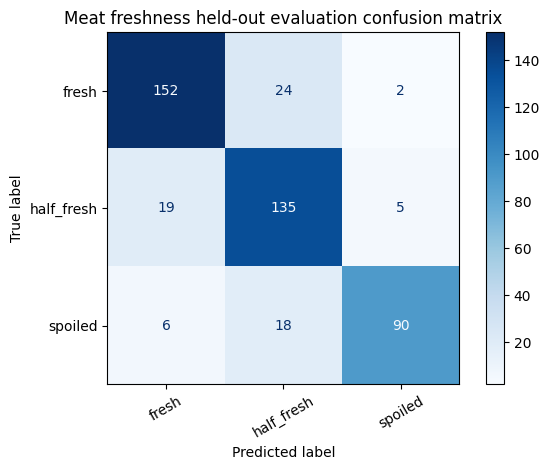

In [4]:
from sklearn.metrics import ConfusionMatrixDisplay

for metric in ('accuracy', 'balanced_accuracy', 'precision_macro', 'recall_macro', 'f1_macro'):
    print(f'{metric}: {metrics[metric]:.4f}')
print('\nPer-class report:')
for name in class_names:
    print(name, metrics['classification_report'][name])
ConfusionMatrixDisplay(np.asarray(metrics['confusion_matrix']), display_labels=class_names).plot(cmap='Blues', xticks_rotation=30)
plt.title('Meat freshness held-out evaluation confusion matrix')
plt.tight_layout()
plt.show()

## 4. Single-image prediction and production pipeline

The following cell predicts one held-out image and compares the output with its folder label. The FastAPI application exposes the same prediction function, a browser UI, health and metrics routes, image uploads, and a retraining trigger. Uploaded labelled images are saved in SQLite and freshness-class folders before `partial_fit` updates the existing model.

In [5]:
from src.prediction import predict_image

sample_path = next(path for name in class_names for path in sorted((TEST_DIR / name).iterdir()) if path.suffix.lower() in IMAGE_EXTENSIONS)
with sample_path.open('rb') as image_file:
    prediction = predict_image(image_file.read())
actual = sample_path.parent.name
print('Image:', sample_path.name)
print('Actual:', actual)
print('Predicted:', prediction['prediction'])
print('Confidence:', round(prediction['confidence'], 4))
print('Top predictions:', prediction['top_predictions'])

Image: FRESH-10-_JPG.rf.b39881c9ff5786aac7f0b9f6f76deb58.jpg
Actual: fresh
Predicted: fresh
Confidence: 1.0
Top predictions: [{'label': 'fresh', 'confidence': 1.0}, {'label': 'spoiled', 'confidence': 0.0}, {'label': 'half_fresh', 'confidence': 0.0}]


## 5. Retraining and deployment checklist

- Start the web app with `uvicorn app.main:app --host 0.0.0.0 --port 8000` and open `/` or `/docs`.
- Upload new photos with a known freshness label; the API records each upload and saves it in `data/meat_freshness/uploads/<class-id>/`.
- Press **Trigger retraining**. The saved fitted classifier is updated with `partial_fit`; inspect `/retrain/status` for history.
- For Locust, run `locust -f locustfile.py --host http://127.0.0.1:8000` and record results at 10, 50, and 100 users. Do not invent latency or deployment results.
- Keep the labelled dataset private/local; it is not included in the repository. This model is for an image-classification assignment only, not for food-safety decisions.